# 第20步 表图与数值来源整理

仅读取既有分析结果并计算描述性人群表，不拟合新模型、不做新检验、不起草论文正文。原第18步为主分析，全部敏感性结果保留。

In [1]:
from pathlib import Path
import sys,json,hashlib,importlib.util
import pandas as pd
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
spec=importlib.util.spec_from_file_location('paper_materials',ROOT/'scripts/make_ucsd_paper_materials.py')
module=importlib.util.module_from_spec(spec);spec.loader.exec_module(module)
package=module.generate(ROOT)
print('Tables / figures:',len(package['tables']),len(package['figures']))
print('Manuscript body drafted:',package['manuscript_body_drafted'])

Tables / figures: 11 5
Manuscript body drafted: False


In [2]:
for table in package['tables']:
    print(table['title'])
    print(pd.DataFrame(table['rows'],columns=table['headers']).to_string(index=False))

表1 主影像队列的临床特征
          指标              全部影像扫描               肿瘤扫描               治疗改变扫描
       扫描记录数                 182                141                   41
        源患者数                 135                114                   29
        年龄，岁   56.5 [49.0, 66.0]  58.0 [50.0, 67.0]    54.0 [48.0, 62.0]
          男性     132/182 (72.5%)    105/141 (74.5%)        27/41 (65.9%)
        肿瘤扫描     141/182 (77.5%)   141/141 (100.0%)          0/41 (0.0%)
      治疗改变扫描      41/182 (22.5%)       0/141 (0.0%)       41/41 (100.0%)
距初始事件天数，已知记录 154.0 [40.5, 359.5] 96.0 [36.0, 261.8] 346.0 [140.5, 563.2]
      间隔已知记录     146/182 (80.2%)    108/141 (76.6%)        38/41 (92.7%)
      间隔缺失记录      36/182 (19.8%)     33/141 (23.4%)          3/41 (7.3%)
     扫描前其他治疗      25/182 (13.7%)     20/141 (14.2%)         5/41 (12.2%)
表2 主分析的患者分组OOF性能
    模型      AUC  CI_lower  CI_upper    Brier    AP_TC  TC_correct  TC_total
 年龄＋性别 0.525515  0.403964  0.644101 0.176697 0.261331           0        41
  扩展临床 0.67211

In [3]:
clinical=pd.read_csv(ROOT/'data/processed/ucsd_clinical_revalidated_cohort.csv')
image=pd.read_csv(ROOT/'data/processed/ucsd_clinical_image_features.csv')
assert len(clinical)==238 and len(image)==182
assert image.patient_id.nunique()==135
print('Class-specific unique patient counts:',image.groupby('tumor_label').patient_id.nunique().to_dict())
print('Overlap patients across labels:',len(set(image.loc[image.tumor_label.eq(0),'patient_id'])&set(image.loc[image.tumor_label.eq(1),'patient_id'])))
print('Baseline summaries use scan rows; no group p-values.')

Class-specific unique patient counts: {0: 29, 1: 114}
Overlap patients across labels: 8
Baseline summaries use scan rows; no group p-values.


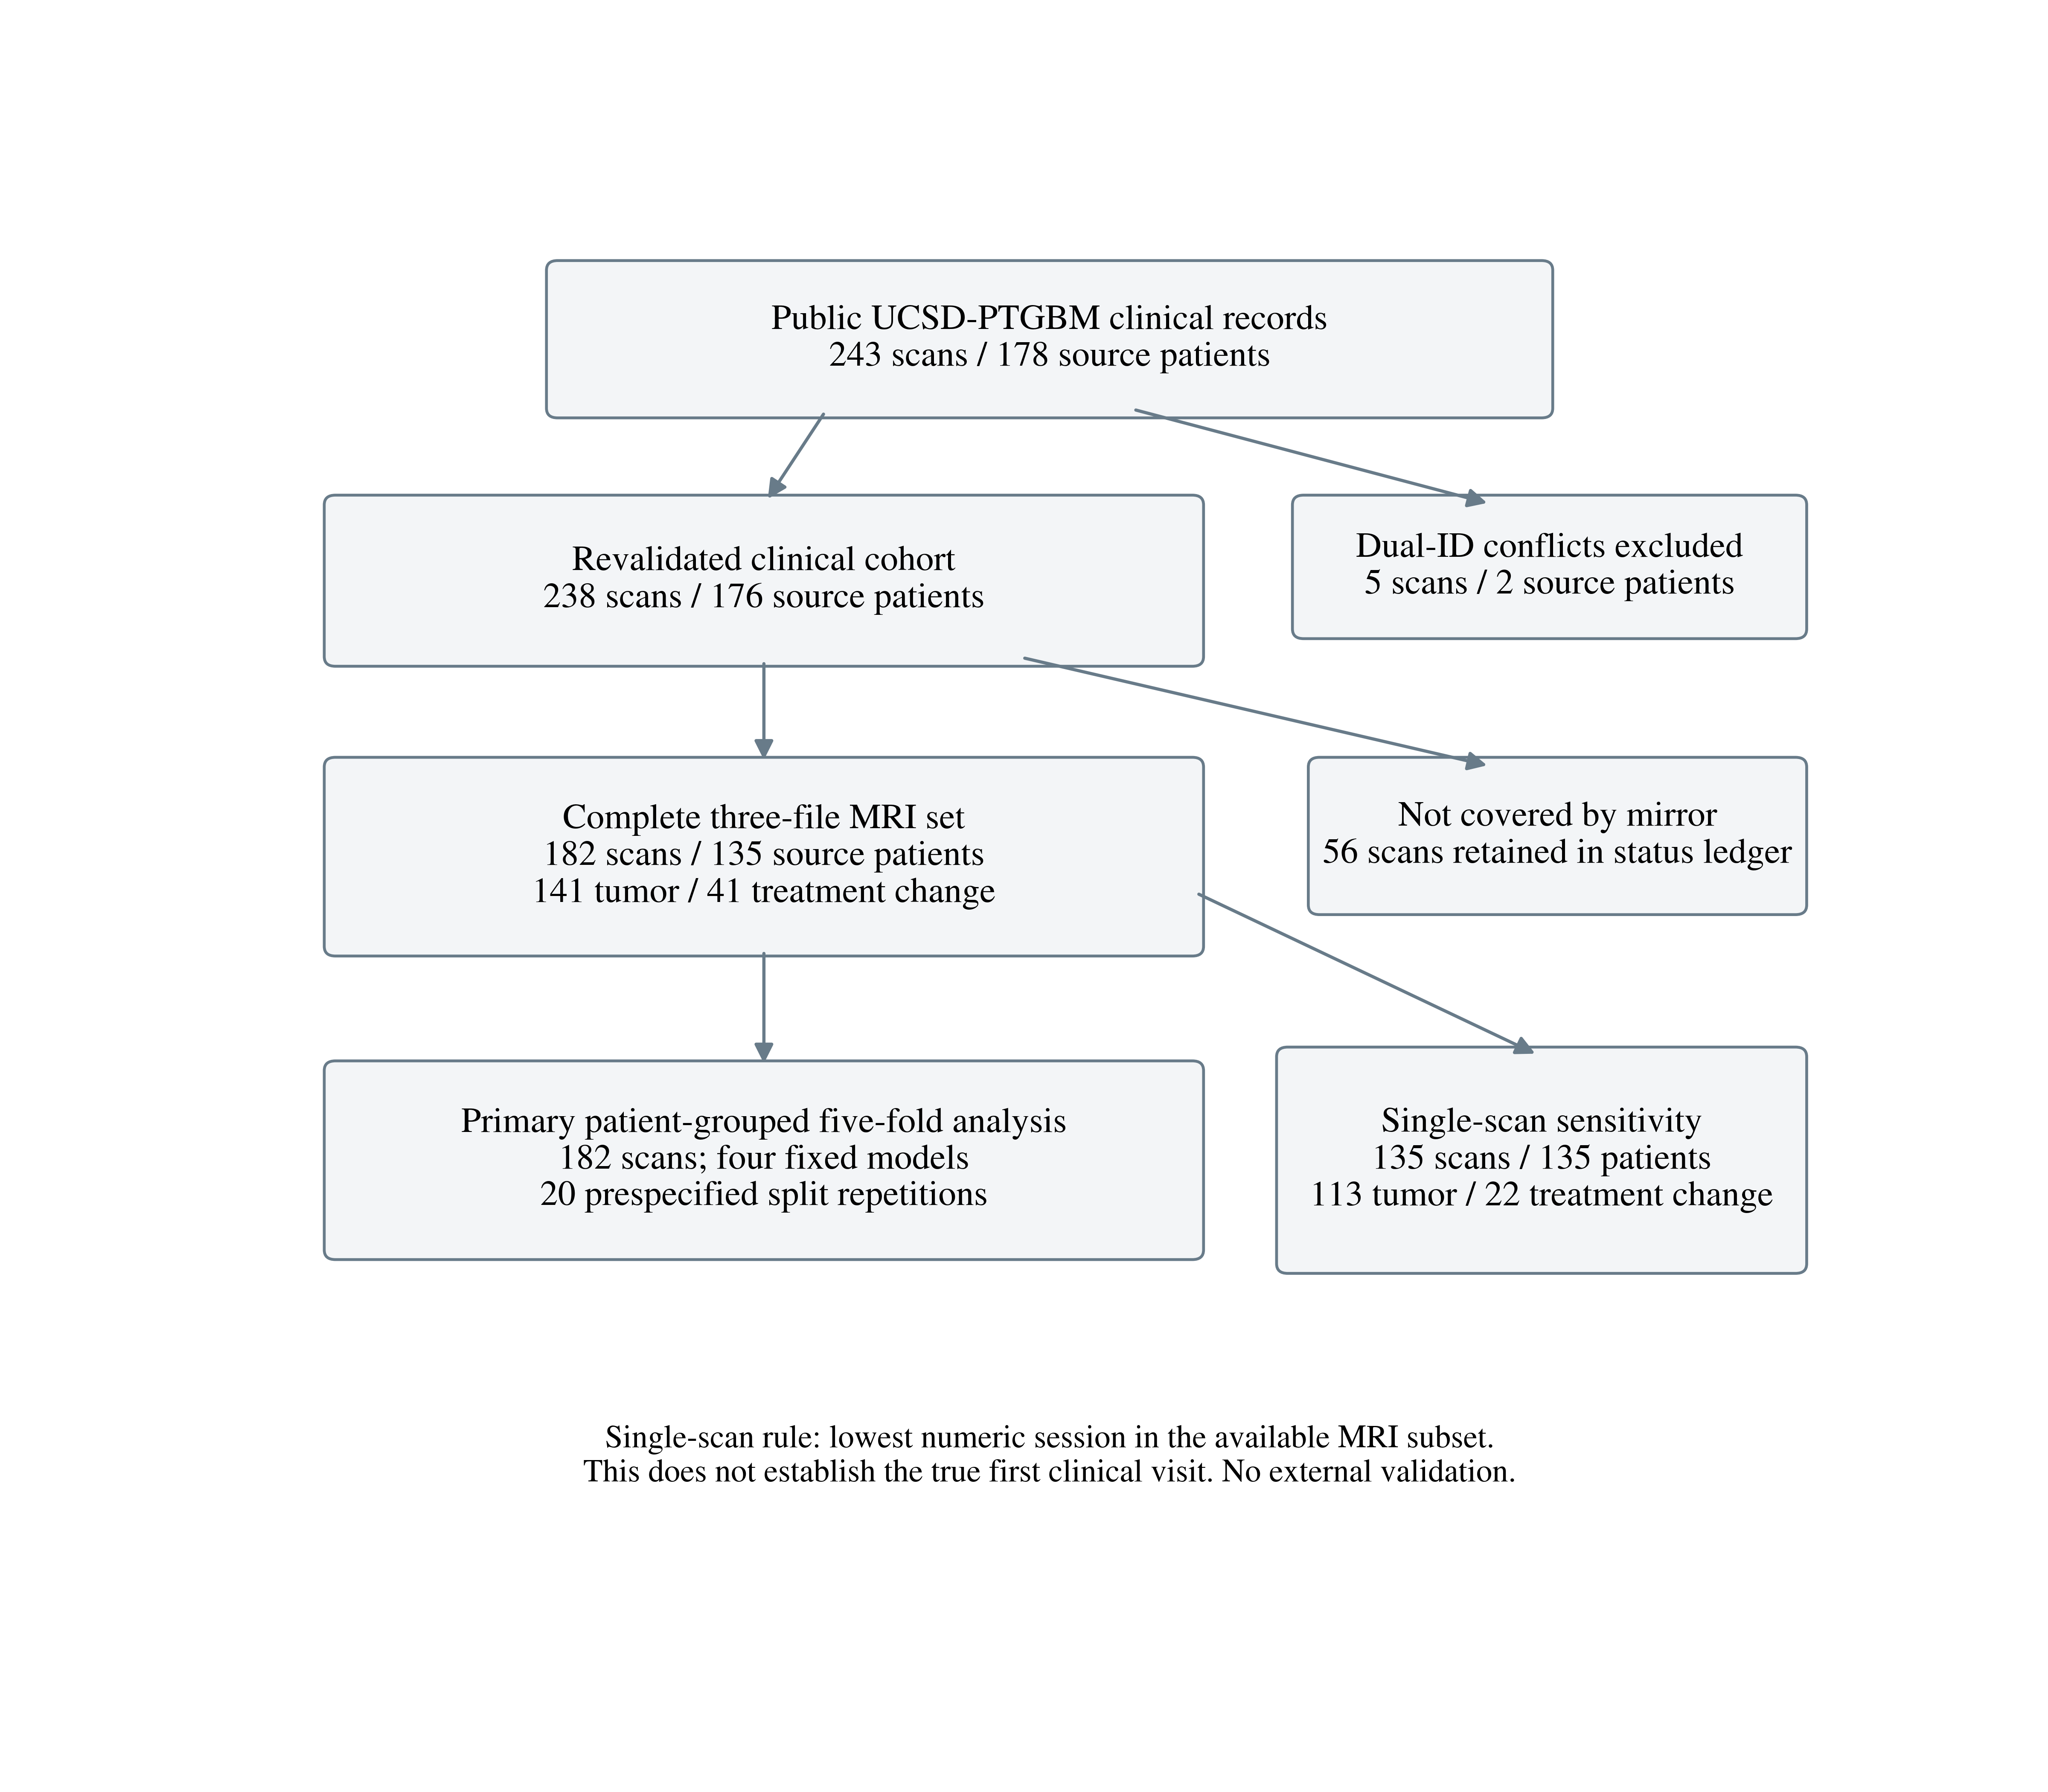

In [4]:
from IPython.display import display,Image
figdir=ROOT/'outputs/ucsd-paper-materials-20261029/figures'
display(Image(filename=str(figdir/'Figure1_Cohort_Flow.png'),width=650))
display(Image(filename=str(figdir/'Figure2_Main_Comparison.png'),width=1100))

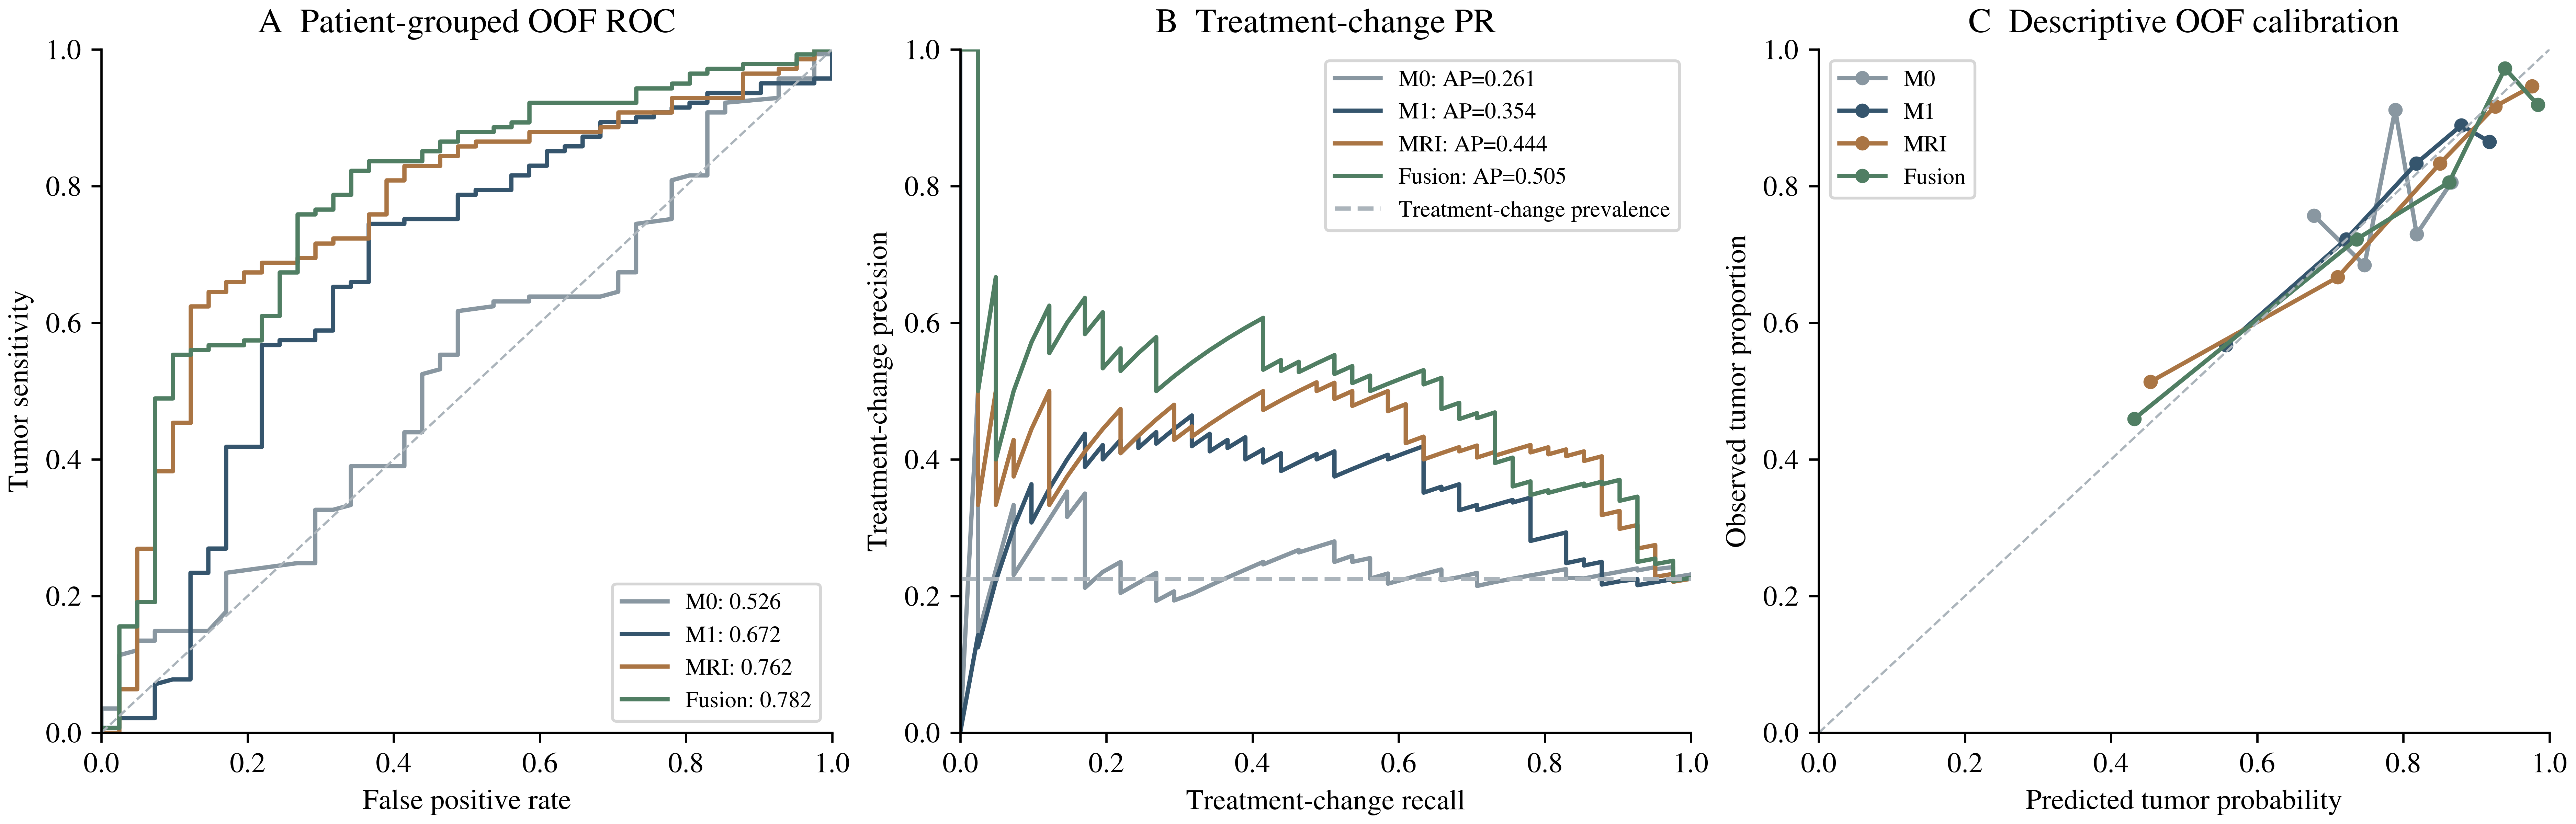

Frozen sources verified; manuscript writing awaits user instructions.


In [5]:
receipt=json.loads((ROOT/'reports/ucsd_paper_materials/generation_receipt.json').read_text())
for p,h in receipt['input_sha256'].items():
    assert hashlib.sha256((ROOT/p).read_bytes()).hexdigest()==h
assert receipt['model_refits']==0 and receipt['new_hypothesis_tests']==0
print('Frozen sources verified; manuscript writing awaits user instructions.')